In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

print("TensorFlow and Keras libraries imported.")

TensorFlow and Keras libraries imported.


In [2]:
mnist = keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalize pixel values to be between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Reshape data to fit FCNN input: (num_samples, 28, 28) -> (num_samples, 784)
x_train = x_train.reshape((x_train.shape[0], -1))
x_test = x_test.reshape((x_test.shape[0], -1))

print(f"Training data shape: {x_train.shape}")
print(f"Training labels shape: {y_train.shape}")
print(f"Test data shape: {x_test.shape}")
print(f"Test labels shape: {y_test.shape}")

print("MNIST dataset loaded and preprocessed for TensorFlow/Keras.")

Training data shape: (60000, 784)
Training labels shape: (60000,)
Test data shape: (10000, 784)
Test labels shape: (10000,)
MNIST dataset loaded and preprocessed for TensorFlow/Keras.


In [3]:
input_size = 28 * 28 # MNIST images are 28x28
hidden_size1 = 128
hidden_size2 = 64
num_classes = 10
num_epochs = 5
batch_size = 64

print("Hyperparameters defined.")

Hyperparameters defined.


In [4]:
model_tf = models.Sequential([
    layers.InputLayer(input_shape=(input_size,)),
    layers.Dense(hidden_size1, activation='relu'),
    layers.Dense(hidden_size2, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model_tf.summary()
print("TensorFlow/Keras FCNN model defined.")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

TensorFlow/Keras FCNN model defined.


In [5]:
model_tf.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("TensorFlow/Keras model compiled with Adam optimizer and Sparse Categorical Crossentropy loss.")

TensorFlow/Keras model compiled with Adam optimizer and Sparse Categorical Crossentropy loss.


In [6]:
history = model_tf.fit(x_train, y_train, epochs=num_epochs, batch_size=batch_size, verbose=1, validation_data=(x_test, y_test))

print("TensorFlow/Keras model training completed.")

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8520 - loss: 0.5113 - val_accuracy: 0.9603 - val_loss: 0.1315
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9639 - loss: 0.1217 - val_accuracy: 0.9717 - val_loss: 0.0938
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9762 - loss: 0.0782 - val_accuracy: 0.9752 - val_loss: 0.0816
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9821 - loss: 0.0575 - val_accuracy: 0.9780 - val_loss: 0.0756
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9867 - loss: 0.0415 - val_accuracy: 0.9748 - val_loss: 0.0804
TensorFlow/Keras model training completed.


In [7]:
test_loss_tf, test_accuracy_tf = model_tf.evaluate(x_test, y_test, verbose=0)

print(f"TensorFlow/Keras Final Test Loss: {test_loss_tf:.4f}")
print(f"TensorFlow/Keras Final Test Accuracy: {test_accuracy_tf * 100:.2f}%")

TensorFlow/Keras Final Test Loss: 0.0804
TensorFlow/Keras Final Test Accuracy: 97.48%


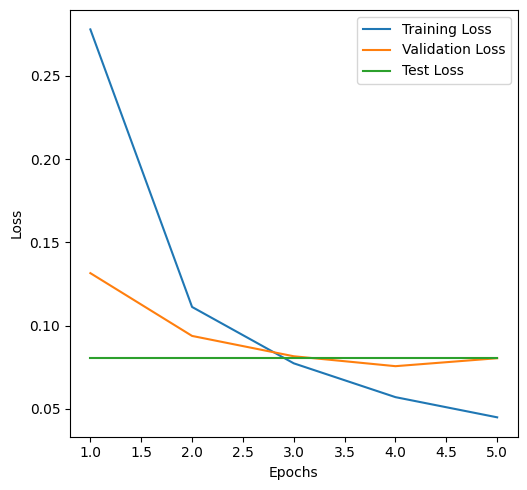

Plots generated for Training, Validation and Test loss


In [8]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, history.history['loss'], label='Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.plot(epochs, history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.plot(epochs, [test_loss_tf] * len(epochs), label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

print("Plots generated for Training, Validation and Test loss")